# Vertebra renderings in latent space: from data plot to cover image

Builds up from the latent-code embeddings to an artistic journal-cover rendering:

1. **Setup**: paths, config and mesh-path remap
2. **Functions**: everything reusable, in one cell
3. **Data**: filenames, latent codes and the family / species colours
4. **Render**: one vertebra to check the camera view, then all of them (cached)
5. **Full embeddings**: PCA and t-SNE with every vertebra drawn as its rendering
6. **Species means**: one C5 per species at its mean latent code
7. **Cover**: tapering vertebral-column curves, repelled thumbnails and a pencil-style key

Each cell's parameters are set at its top. Renders are cached per view, so re-plotting is fast.

In [1]:
# Setup: imports, paths, config

import os, re, json, gc, colorsys, urllib.request
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import torch
import cv2
import pyvista as pv
import open3d as o3d
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import font_manager
from matplotlib.collections import LineCollection
from matplotlib.font_manager import FontProperties
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import PathPatch
from matplotlib.textpath import TextPath
from matplotlib.transforms import Affine2D
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from NSM.helper_funcs import pv_to_o3d, render_cameras

RUN      = "run_v72"                               # TO DO: training attempt directory
OLD_ROOT = "/home/k.wolcott/NSM/nsm/"              # mesh-path prefix stored in the config
NEW_ROOT = "/home/kaubricot/Downloads/NSM/nsm/"    # where the meshes live on this machine
DPI_SAVE = 400                                     # resolution of every saved PNG

os.chdir(Path.cwd().parent / RUN)
print(f"Working directory: {os.getcwd()}")

with open("model_params_config.json") as f:
    cfg = json.load(f)

train_paths = [re.sub(rf"^{re.escape(OLD_ROOT)}", NEW_ROOT, p) for p in cfg["list_mesh_paths"]]
n_found = sum(os.path.exists(p) for p in train_paths)
print(f"{len(train_paths)} meshes in config; {n_found} found under {NEW_ROOT}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
schedulefree not found, skipping import
Working directory: /home/kaubricot/Downloads/NSM/nsm/run_v72
2316 meshes in config; 2316 found under /home/kaubricot/Downloads/NSM/nsm/


In [2]:
# Functions

# ---------------------------------------------------------------- colours (unchanged from the PCA plotting script)

def sort_key(item):
    region_order = {'C': 0, 'T': 1, 'L': 2}
    v = item[0]
    return (region_order.get(v[0], 99), int(v[1:]))

def extract_family(species_label):
    family = species_label.split('_')[0]
    species_label = species_label.lower()

    if any(k in species_label for k in ["scincus", "scincidae"]):
        family = "Scincidae"
    elif "ouroborus" in species_label:
        family = "Cordylidae_Ouroborus"
    elif any(k in species_label for k in ["gerrhosaurus", "gerrho"]):
        family = "Gerrhosauridae"
    elif any(k in species_label for k in ["chamaeleo", "iguana", "agamidae", "anolidae", "corytophanidae",
                                          "crotaphytidae", "hoplocercidae", "leiocephalidae", "leiosauridae",
                                          "phrynosomatidae", "tropiduridae", "polycrotidae", "chamaeleonidae"]):
        family = "Iguania"
    elif any(k in species_label for k in ["anguidae", "lanthanotus", "varanus", "shinosaurus", "heloderma", "xenosauridae"]):
        family = "Anguimorpha"
    elif any(k in species_label for k in ["lacertidae", "lacerta", "teiidae", "gymnopthalmidae", "gymothalmidae"]):
        family = "Laterata"
    elif any(k in species_label for k in ["bipes", "rhineura", "diplometopon"]):
        family = "Amphisbaenea"
    elif any(k in species_label for k in ["gecko", "tarentola", "eublepharis", "aristelliger", "phyllurus", "lialis", "gekkota"]):
        family = "Gekkota"
    elif any(k in species_label for k in ["eryx", "homalopsis", "aniolios"]):
        family = "Snake"
    elif "xantusiidae" in species_label:
        family = "Xantusiidae"
    elif "dibamus" in species_label:
        family = "Dibamidae"
    elif "sphenodon" in species_label:
        family = "Rhynchocephalia"

    return family

def make_family_cmap(families):
    default_col = np.array([0.52, 0.52, 0.52])  # grey
    family_base_colors = {
        "iguania": np.array([0.78, 0.16, 0.16]),               # auburn
        "anguimorpha": np.array([1.00, 0.79, 0.20]),           # saffron
        "cordylidae": np.array([0.10, 0.51, 0.40]),            # dark teal
        "cordylidae_ouroborus": np.array([0.082, 0.76, 0.92]), # turquoise - blue
        "gekkota": np.array([0.41, 0.227, 0.6]),               # dark lilac
        "gerrhosauridae": np.array([0.98, 0.39, 0.14]),        # orange
        "scincidae": np.array([0.65, 0.69, 0.12]),             # apple green
        "amphisbaenea": np.array([0.60, 0.50, 0.46]),          # warm slate
        "laterata": np.array([0.145, 0.39, 0.075]),            # forest green
        "xantusiidae": np.array([0.88, 0.74, 0.59])            # emoji white
    }
    family_colors = {}
    for family in families:
        family_colors[family] = family_base_colors.get(family.lower(), default_col)
    return family_colors

def generate_species_cmap_gradient(family_base_colors, species_groups, max_shift=0.4):
    species_colors = {}
    family_species_map = defaultdict(list)
    for species in species_groups:
        family_species_map[extract_family(species)].append(species)
    for family, species_list in family_species_map.items():
        base_rgb = family_base_colors.get(family, np.array([0.7, 0.7, 0.7]))
        base_hls = colorsys.rgb_to_hls(*base_rgb)
        sorted_species = sorted(species_list)
        n = len(sorted_species)
        center_idx = n // 2
        for i, sp in enumerate(sorted_species):
            if i == center_idx:
                new_rgb = base_rgb
            else:
                shift_direction = -1 if i < center_idx else 1
                shift_amount = (abs(i - center_idx) / (n - 1)) * max_shift
                new_lightness = np.clip(base_hls[1] + shift_direction * shift_amount, 0, 1)
                new_rgb = colorsys.hls_to_rgb(base_hls[0], new_lightness, base_hls[2])
            species_colors[sp] = tuple(np.clip(new_rgb, 0, 1)) + (1.0,)
    return species_colors

# ---------------------------------------------------------------- data

FILENAME_PAT = re.compile(r"^(?P<species>[\w\s\-]+)[\-_ ]+[\w\d]+[\-_ ]+(?P<vertebra>[CTL]?\d+)", re.IGNORECASE)

def load_dataset(paths):
    """Parse species / vertebra from filenames and build the colour tables.
    Returns a namespace: paths, labels, sp_idx (species -> mesh indices), species_list,
    family_colors, species_colors."""
    labels = []
    for p in paths:
        m = FILENAME_PAT.match(os.path.basename(p))
        labels.append((m.group("species").strip(), m.group("vertebra").strip()) if m else (None, None))
    sp_idx = defaultdict(list)
    for i, (sp, v) in enumerate(labels):
        if sp is not None and v is not None:
            sp_idx[sp].append(i)
    species_list  = sorted(sp_idx)
    family_colors = make_family_cmap(sorted({extract_family(sp) for sp in species_list}))
    return SimpleNamespace(paths=paths, labels=labels, sp_idx=dict(sp_idx), species_list=species_list,
                           family_colors=family_colors,
                           species_colors=generate_species_cmap_gradient(family_colors, species_list))

def load_latent_codes(ckpt):
    return torch.load(f"latent_codes/{ckpt}.pth", map_location="cpu")["latent_codes"]["weight"].detach().cpu().numpy()

def species_means(D, X):
    """Mean of rows of X per species, in D.species_list order."""
    return np.stack([X[D.sp_idx[sp]].mean(axis=0) for sp in D.species_list])

def representative_vertebra(D, target="C5"):
    """Index of each species' target vertebra, or its nearest available one."""
    order = {"C": 0, "T": 1, "L": 2}
    t = target.upper()
    def dist(v):
        v = v.upper()
        return (abs(order.get(v[0], 9) - order[t[0]]), abs(int(v[1:]) - int(t[1:])))
    return {sp: min(D.sp_idx[sp], key=lambda k: dist(D.labels[k][1])) for sp in D.species_list}

# ---------------------------------------------------------------- rendering (life-history exemplar style)

_RENDERERS = {}   # Open3D offscreen renderers are reused, since re-creating them can crash the kernel

class VertebraRenderer:
    """White, lit render of a vertebra for one camera view, keyed out to a transparent RGBA image.
    Matches the exemplar panel: same renderers, material, rotation and camera crops. Cached as PNG."""

    def __init__(self, view, views, cache_dir, width=640, height=480, rot_deg=13,
                 key_bg=(0.0, 1.0, 0.0), key_tol=60):
        self.crop_key, self.deg = views[view]
        self.view, self.w, self.h, self.key_tol = view, width, height, key_tol
        self.rot = o3d.geometry.get_rotation_matrix_from_axis_angle([0, 0, np.deg2rad(rot_deg)])
        self.cache_dir = Path(cache_dir); self.cache_dir.mkdir(parents=True, exist_ok=True)
        if (width, height) not in _RENDERERS:
            _RENDERERS[(width, height)] = [o3d.visualization.rendering.OffscreenRenderer(width, height)
                                           for _ in range(4)]
        self.renderers = _RENDERERS[(width, height)]
        for r in self.renderers:
            r.scene.set_background(list(key_bg) + [1.0])
        self.mat = o3d.visualization.rendering.MaterialRecord()
        self.mat.shader     = "defaultLit"
        self.mat.base_color = [1.0, 1.0, 1.0, 1.0]

    def __call__(self, mesh_path):
        out_png = self.cache_dir / f"{Path(mesh_path).stem}_{self.view}.png"
        if out_png.exists():
            return plt.imread(out_png)
        mesh   = self._build_mesh(mesh_path)
        panels = render_cameras(self.renderers, mesh, 0, self.mat, 1, n_rotations=1)
        rgba   = self._key_to_rgba(self._crop(panels).copy())
        plt.imsave(out_png, np.clip(rgba, 0, 1))
        del mesh, panels
        gc.collect()
        return rgba

    def _build_mesh(self, mesh_path):
        pv_mesh = pv.read(str(mesh_path))
        pv_mesh = pv_mesh.extract_surface(algorithm="dataset_surface").triangulate()
        pv_mesh = pv_mesh.compute_normals(cell_normals=False, point_normals=True,
                                          inplace=False, auto_orient_normals=True)
        bone = pv_to_o3d(pv_mesh)
        bone.compute_vertex_normals()
        bone.paint_uniform_color([1.0, 1.0, 1.0])
        bone.rotate(self.rot, center=bone.get_center())
        if self.deg:
            R = o3d.geometry.get_rotation_matrix_from_axis_angle([0, 0, np.deg2rad(self.deg)])
            bone.rotate(R, center=bone.get_center())
        return bone

    def _crop(self, panels):
        h, w = self.h, self.w
        return {"top_left":    panels[:h, :w], "top_right":    panels[:h, w:],
                "bottom_left": panels[h:, :w], "bottom_right": panels[h:, w:]}[self.crop_key]

    def _key_to_rgba(self, cell_bgr, pad=4):
        key = cell_bgr[2, 2].astype(int)                       # corner is always background
        bg  = (np.abs(cell_bgr.astype(int) - key) < self.key_tol).all(axis=2)
        rgb = cv2.cvtColor(cell_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255
        rgb[..., 1] = np.minimum(rgb[..., 1], np.maximum(rgb[..., 0], rgb[..., 2]))   # remove green edge spill
        alpha = cv2.GaussianBlur((~bg).astype(np.float32), (3, 3), 0)                 # soften the silhouette
        img = np.dstack([rgb, alpha])
        ys, xs = np.nonzero(alpha > 0.01)
        if len(ys) == 0:
            return img
        return img[max(ys.min() - pad, 0):ys.max() + pad + 1, max(xs.min() - pad, 0):xs.max() + pad + 1]

def tint(img, color, floor=0.45, gamma=0.7, highlight=0.25):
    """Colour a white shaded render: keeps the shading, stays close to the true colour."""
    out   = img.copy()
    shade = img[..., :3].mean(axis=2)
    lit   = shade[img[..., 3] > 0.5]
    shade = np.clip(shade / (np.percentile(lit, 99) if lit.size else 1), 0, 1) ** gamma
    rgb   = np.asarray(color[:3], dtype=np.float32) * (floor + (1 - floor) * shade[..., None])
    rgb  += (1 - rgb) * highlight * shade[..., None] ** 4
    out[..., :3] = np.clip(rgb, 0, 1)
    return out

# ---------------------------------------------------------------- plotting

def repel(ax, xy, radius_px, overlap=0.6, spring=0.02, iters=400, step=0.5):
    """Push overlapping thumbnails apart in screen space; returns new positions in data units.
    overlap: 1 = edges just touch; spring: pull back toward the true position; step: push strength."""
    ax.figure.canvas.draw()                                    # lock in layout and axis limits
    ax.autoscale(False)
    P0 = ax.transData.transform(xy)
    P  = P0 + np.random.default_rng(0).normal(0, 0.5, P0.shape)   # separates exact duplicates
    min_d = 2 * radius_px * overlap
    for _ in range(iters):
        pairs = cKDTree(P).query_pairs(min_d, output_type="ndarray")   # only nearby pairs: scales to thousands
        if len(pairs) == 0:
            break
        i, j = pairs.T
        d    = P[i] - P[j]
        dist = np.linalg.norm(d, axis=1) + 1e-9
        ov   = min_d - dist
        if ov.max() < 0.5:
            break
        f = d / dist[:, None] * ov[:, None]
        push = np.zeros_like(P)
        np.add.at(push, i, f)
        np.add.at(push, j, -f)
        P += step * push + spring * (P0 - P)
    return ax.transData.inverted().transform(P)

def place_thumbs(ax, xy, imgs, thumb_pt, alpha=1.0, zorder=3):
    """Draw images at xy, lower ones in front; longest side = thumb_pt points."""
    for k in np.argsort(-xy[:, 1]):
        img = imgs[k]
        if alpha < 1:
            img = img.copy(); img[..., 3] *= alpha
        ab = AnnotationBbox(OffsetImage(img, zoom=thumb_pt / max(img.shape[:2]), interpolation="lanczos"),
                            xy[k], frameon=False, pad=0)
        ab.set_zorder(zorder)
        ax.add_artist(ab)

def draw_leaders(ax, start, end, colors, lw=0.3, alpha=0.4):
    """Hairlines from true positions to repelled ones (zero-length lines draw nothing)."""
    for (x0, y0), (x1, y1), c in zip(start, end, colors):
        ax.plot([x0, x1], [y0, y1], color=c, lw=lw, alpha=alpha, zorder=2, solid_capstyle="butt")

def save_fig(fig, out, dpi, tight=True, facecolor="white"):
    kw = dict(bbox_inches="tight") if tight else {}
    fig.savefig(out + ".png", dpi=dpi, facecolor=facecolor, **kw)
    fig.savefig(out + ".pdf", facecolor=facecolor, **kw)
    print(f"Saved -> {out}.png / .pdf")

def plot_thumbs(xy, imgs, out, *, xlabel="", ylabel="", figsize=(16, 12), thumb_pt=30, vert_alpha=1.0,
                repel_kw=None, leader_colors=None, show_axes=True, legend_colors=None, dpi=400):
    """Scatter plot with each point drawn as its vertebra rendering.
    repel_kw: None for true positions, or kwargs for repel() plus 'radius_scale'."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.update_datalim(xy); ax.autoscale_view(); ax.margins(0.06)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if show_axes:
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)
    else:
        ax.axis("off")
    if legend_colors:
        ax.legend(handles=[mpatches.Patch(color=c, label=f) for f, c in legend_colors.items()],
                  loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, title="Family")
    fig.tight_layout()                                         # settle the layout before measuring overlaps

    pos = xy
    if repel_kw:
        kw  = dict(repel_kw)
        pos = repel(ax, xy, kw.pop("radius_scale", 0.5) * thumb_pt * fig.dpi / 72, **kw)
        if leader_colors is not None:
            draw_leaders(ax, xy, pos, leader_colors)
    place_thumbs(ax, pos, imgs, thumb_pt, vert_alpha)
    save_fig(fig, out, dpi)
    plt.show()

# ---------------------------------------------------------------- cover

def chaikin(pts, n_iter=3):
    """Corner-cutting smoothing: scale-free, keeps the curve near the real points."""
    pts = pts[np.r_[True, np.any(np.diff(pts, axis=0) != 0, axis=1)]]
    for _ in range(n_iter if len(pts) > 2 else 0):
        q = 0.75 * pts[:-1] + 0.25 * pts[1:]
        r = 0.25 * pts[:-1] + 0.75 * pts[1:]
        pts = np.vstack([pts[0], np.column_stack([q, r]).reshape(-1, 2), pts[-1]])
    return pts

def tapered_line(ax, pts, color, widths, alphas, zorder=1):
    """Line whose width and opacity change linearly from start to end."""
    if len(pts) < 2:
        return
    seg  = np.stack([pts[:-1], pts[1:]], axis=1)
    t    = np.linspace(0, 1, len(seg))
    rgba = np.tile(np.r_[color[:3], 1.0], (len(seg), 1))
    rgba[:, 3] = alphas[0] + (alphas[1] - alphas[0]) * t
    lw   = widths[0] + (widths[1] - widths[0]) * t
    ax.add_collection(LineCollection(seg, colors=rgba, linewidths=lw, capstyle="butt",
                                     joinstyle="miter", antialiased=True, zorder=zorder))

HAND_FONTS = {   # Google Fonts, free licences
    "homemade_apple":       "apache/homemadeapple/HomemadeApple-Regular.ttf",   # loopy, pencil-like
    "nothing_you_could_do": "ofl/nothingyoucoulddo/NothingYouCouldDo.ttf",      # quick, scrawly
    "cedarville":           "ofl/cedarvillecursive/Cedarville-Cursive.ttf",     # neat schoolbook cursive
    "la_belle_aurore":      "ofl/labelleaurore/LaBelleAurore.ttf",              # flowing, big loops
}

def load_hand_font(name, font_dir="fonts"):
    """Download (once) and register a handwritten font; returns FontProperties."""
    font_dir = Path(font_dir); font_dir.mkdir(exist_ok=True)
    path = font_dir / Path(HAND_FONTS[name]).name
    if not path.exists():
        urllib.request.urlretrieve("https://raw.githubusercontent.com/google/fonts/main/" + HAND_FONTS[name], path)
    font_manager.fontManager.addfont(str(path))
    return FontProperties(fname=str(path))

def format_taxon(taxon, rename=None, case="regular"):
    name = (rename or {}).get(taxon, taxon).replace("_", " ")
    if case == "upper":
        return name.upper()
    if case == "title":
        return name.title()
    return name[0].upper() + name[1:]

def pencil_text(ax, text, x, y, color, rng, font, size, passes, fill_alpha, jitter, fade):
    """Coloured-pencil text: layered, slightly offset fills that fade left to right."""
    tp  = TextPath((0, 0), text, size=size, prop=font)
    ext = tp.get_extents()
    dx  = x - ext.x0
    grad = np.zeros((1, 256, 4))
    grad[..., :3] = np.asarray(color[:3], dtype=float)
    grad[..., 3]  = np.linspace(fade[0], fade[1], 256) * fill_alpha
    for p in range(passes):
        ox, oy = (0, 0) if p == 0 else rng.normal(0, jitter, 2)
        clip = PathPatch(Affine2D().translate(dx + ox, y + oy).transform_path(tp),
                         transform=ax.transData, facecolor="none", edgecolor="none")
        im = ax.imshow(grad, extent=[dx + ext.x0 + ox, dx + ext.x1 + ox, y + ext.y0 + oy, y + ext.y1 + oy],
                       aspect="auto", interpolation="bilinear", zorder=1)
        im.set_clip_path(clip)

def key_taxa(D, exclude=()):
    return sorted({extract_family(sp) for sp in D.species_list} - set(exclude), key=str.lower)

def key_height(fig, D, cols, size, leading, exclude=(), **_):
    """Height of the pencil key as a fraction of the page."""
    n_rows = int(np.ceil(len(key_taxa(D, exclude)) / cols))
    return n_rows * size * leading / (fig.get_figheight() * 72)

def pencil_key(fig, D, font, *, left, right, bottom, cols, size, leading, case, passes,
               fill_alpha, jitter, fade, exclude=(), rename=None, **_):
    """Taxon names in family colours, in columns justified across the bottom of the page."""
    h_frac = key_height(fig, D, cols, size, leading, exclude)
    pad_pt = 0.5 * size                                        # room below the last row for descenders
    pad    = pad_pt / (fig.get_figheight() * 72)
    kx = fig.add_axes([left, bottom - pad, right - left, h_frac + pad], facecolor="none")
    kx.axis("off")
    w_pt, h_pt = (right - left) * fig.get_figwidth() * 72, h_frac * fig.get_figheight() * 72
    kx.set_xlim(0, w_pt); kx.set_ylim(-pad_pt, h_pt)           # 1 axis unit = 1 point
    kx.autoscale(False)

    taxa   = key_taxa(D, exclude)
    n_rows = int(np.ceil(len(taxa) / cols))
    groups = [g for g in (taxa[c * n_rows:(c + 1) * n_rows] for c in range(cols)) if g]
    names  = [[format_taxon(t, rename, case) for t in g] for g in groups]
    widths = [max(TextPath((0, 0), n, size=size, prop=font).get_extents().width for n in g) for g in names]
    gap    = (w_pt - sum(widths)) / max(len(groups) - 1, 1)  # equal gaps; first and last columns touch the edges

    rng, x = np.random.default_rng(7), 0.0
    for g, ns, w in zip(groups, names, widths):
        for row, (taxon, name) in enumerate(zip(g, ns)):
            y = h_pt - (row + 1) * size * leading + 0.25 * size   # baseline for this row
            pencil_text(kx, name, x, y, D.family_colors.get(taxon, (0.52, 0.52, 0.52)), rng,
                        font, size, passes, fill_alpha, jitter, fade)
        x += w + gap

def plot_cover(D, coords, rep_imgs, out, *, size, bg, ink, plot_top, spine_w, spine_alpha,
               thumb_pt, vert_alpha, repel_kw=None, key=None, font=None, key_gap=0.005, dpi=400):
    """Each species' vertebral column as a tapering curve, species-mean thumbnails on top,
    and an optional pencil key along the bottom. rep_imgs: one image per species (D.species_list order)."""
    fig = plt.figure(figsize=size, facecolor=bg)
    bottom = key["bottom"] + key_height(fig, D, **key) + key_gap if key else 0.06
    ax = fig.add_axes([0.05, bottom, 0.90, plot_top - bottom], facecolor=bg)
    ax.axis("off")

    allpts = coords[[i for sp in D.species_list for i in D.sp_idx[sp]]]
    ax.update_datalim(allpts); ax.autoscale_view(); ax.margins(x=0.05, y=0.02)

    for sp in D.species_list:
        idx = sorted(D.sp_idx[sp], key=lambda i: sort_key((D.labels[i][1].upper(),)))
        tapered_line(ax, chaikin(coords[idx]), D.species_colors[sp], spine_w, spine_alpha)

    centres = species_means(D, coords)
    pos = centres
    if repel_kw:
        kw  = dict(repel_kw)
        pos = repel(ax, centres, kw.pop("radius_scale", 0.65) * thumb_pt * fig.dpi / 72, **kw)
        draw_leaders(ax, centres, pos, [ink] * len(pos), lw=0.3, alpha=0.35)
    place_thumbs(ax, pos, rep_imgs, thumb_pt, vert_alpha)

    if key:
        pencil_key(fig, D, font, **key)
    save_fig(fig, out, dpi, tight=False, facecolor=bg)
    plt.show()

## Data

In [3]:
# Filenames, latent codes and colours

CKPT = "2000"     # TO DO: latent-code checkpoint

D     = load_dataset(train_paths)
codes = load_latent_codes(CKPT)
n_parsed = sum(sp is not None for sp, _ in D.labels)
print(f"Parsed {n_parsed} / {len(D.labels)} filenames: {len(D.species_list)} species "
      f"in {len(D.family_colors)} families; latent codes {codes.shape}")

Parsed 2316 / 2316 filenames: 94 species in 15 families; latent codes (2316, 512)


You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


## Render the vertebrae

Using 'soft' CircularBuffer (12288 KiB)
FEngine (64 bits) created at 0x561e1bba0c30 (threading is enabled)
FEngine resolved backend: Vulkan
Vulkan device driver: NVIDIA 580.178.04
Selected physical device 'NVIDIA RTX 3500 Ada Generation Laptop GPU' from 3 physical devices. (vendor 0x10de, device 0x27bb, driver 0x912c8100, api 1.4)
Backend feature level: 3
FEngine feature level: 1


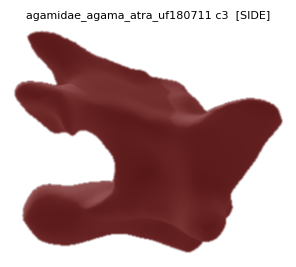

In [4]:
# Check one render before rendering everything

VIEW  = "SIDE"                                 # TO DO: "SIDE", "BACK" or "FRONT"
VIEWS = {"SIDE":  ("top_right",   0),          # (crop of the render_cameras grid, extra z-rotation in degrees)
         "BACK":  ("bottom_left", 180),        # SIDE and BACK match the exemplar panel; FRONT is BACK
         "FRONT": ("bottom_left", 0)}          # without the 180° flip (check it shows the face you expect)
THUMB_DIR = "pca_vertebra_thumbs"              # cache of white renders, one PNG per mesh per view
TINT = dict(floor=0.45,                        # brightness of the darkest shadows (0 = black, 1 = flat colour)
            gamma=0.7,                         # < 1 lifts the midtones
            highlight=0.25)                    # how much the brightest areas fade toward white

render = VertebraRenderer(VIEW, VIEWS, THUMB_DIR)

i0 = D.sp_idx[D.species_list[0]][0]
plt.figure(figsize=(4, 3))
plt.imshow(tint(render(D.paths[i0]), D.species_colors[D.labels[i0][0]], **TINT))
plt.title(f"{D.labels[i0][0]} {D.labels[i0][1]}  [{VIEW}]", fontsize=8)
plt.axis("off"); plt.show()

In [5]:
# Render all vertebrae (cached, so only new ones are rendered) and colour them

SAVE_COLOURED = True                                     # also save coloured transparent PNGs
COLOURED_DIR  = f"cover_image/vert_thumbnails_{VIEW.lower()}"

thumbs, failed = {}, []
valid = [i for sp in D.species_list for i in D.sp_idx[sp]]
for n, i in enumerate(valid, 1):
    try:
        thumbs[i] = render(D.paths[i])
    except Exception as e:
        failed.append((os.path.basename(D.paths[i]), str(e)))
    if n % 50 == 0 or n == len(valid):
        print(f"  {n} / {len(valid)} rendered", flush=True)
if failed:
    print(f"\033[33m{len(failed)} failed:\033[0m", failed[:5])

coloured = {i: tint(img, D.species_colors[D.labels[i][0]], **TINT) for i, img in thumbs.items()}

if SAVE_COLOURED:
    Path(COLOURED_DIR).mkdir(parents=True, exist_ok=True)
    for i, img in coloured.items():
        sp, v = D.labels[i]
        plt.imsave(Path(COLOURED_DIR) / f"{extract_family(sp)}__{sp}__{v.upper()}_{VIEW}.png", np.clip(img, 0, 1))
    print(f"Saved {len(coloured)} coloured thumbnails -> {Path(COLOURED_DIR).resolve()}")

  50 / 2316 rendered
  100 / 2316 rendered
  150 / 2316 rendered
  200 / 2316 rendered
  250 / 2316 rendered
  300 / 2316 rendered
  350 / 2316 rendered
  400 / 2316 rendered
  450 / 2316 rendered
  500 / 2316 rendered
  550 / 2316 rendered
  600 / 2316 rendered
  650 / 2316 rendered
  700 / 2316 rendered
  750 / 2316 rendered
  800 / 2316 rendered
  850 / 2316 rendered
  900 / 2316 rendered
  950 / 2316 rendered
  1000 / 2316 rendered
  1050 / 2316 rendered
  1100 / 2316 rendered
  1150 / 2316 rendered
  1200 / 2316 rendered
  1250 / 2316 rendered
  1300 / 2316 rendered
  1350 / 2316 rendered
  1400 / 2316 rendered
  1450 / 2316 rendered
  1500 / 2316 rendered
  1550 / 2316 rendered
  1600 / 2316 rendered
  1650 / 2316 rendered
  1700 / 2316 rendered
  1750 / 2316 rendered
  1800 / 2316 rendered
  1850 / 2316 rendered
  1900 / 2316 rendered
  1950 / 2316 rendered
  2000 / 2316 rendered
  2050 / 2316 rendered
  2100 / 2316 rendered
  2150 / 2316 rendered
  2200 / 2316 rendered
  2250 /

## Full embeddings: every vertebra

Saved -> run_v72_pca_1v2_vertebrae_side.png / .pdf


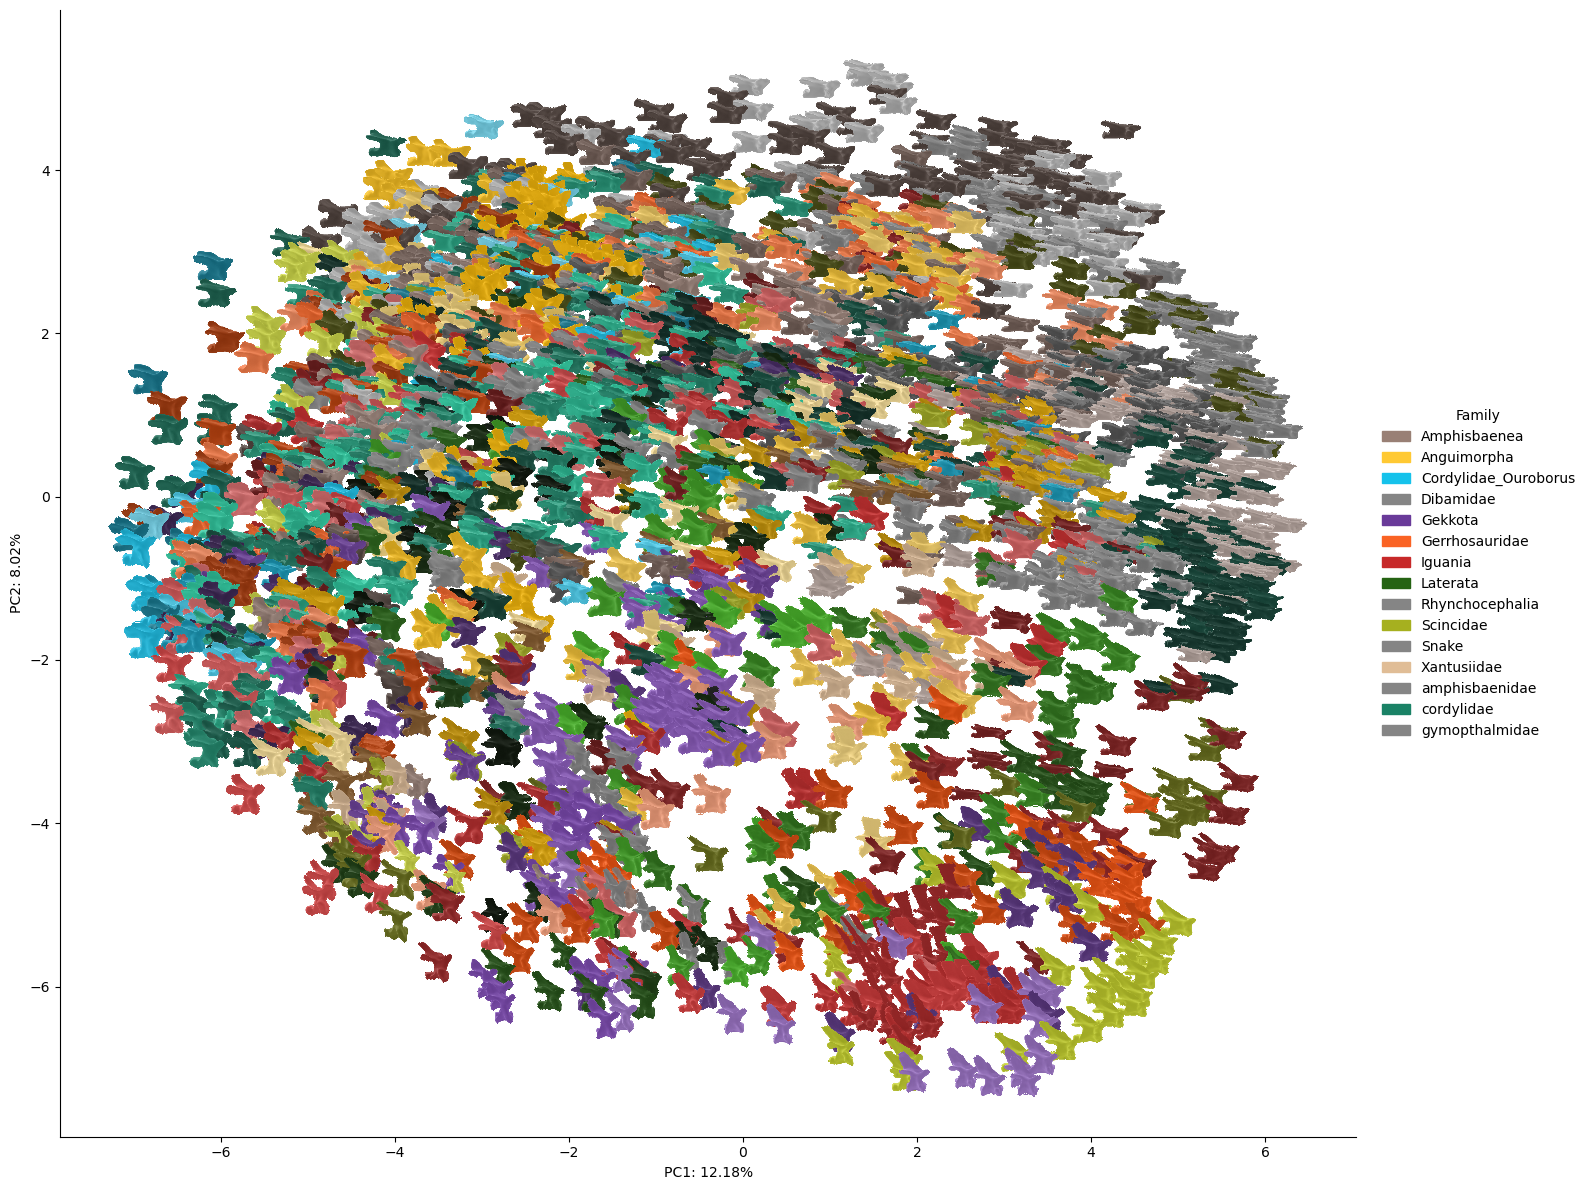

In [6]:
# PCA: PC1 vs PC2, every vertebra drawn as its rendering

N_COMPONENTS = 5
THUMB_PT     = 30        # longest side of each vertebra, in points
SHOW_AXES    = True

pca        = PCA(n_components=N_COMPONENTS)
pca_coords = pca.fit_transform(codes)

idx = np.array(sorted(coloured))
plot_thumbs(pca_coords[idx, :2], [coloured[i] for i in idx], f"{RUN}_pca_1v2_vertebrae_{VIEW.lower()}",
            xlabel=f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%",
            ylabel=f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%",
            thumb_pt=THUMB_PT, show_axes=SHOW_AXES, legend_colors=D.family_colors, dpi=DPI_SAVE)

Saved -> run_v72_tsne_vertebrae_side.png / .pdf


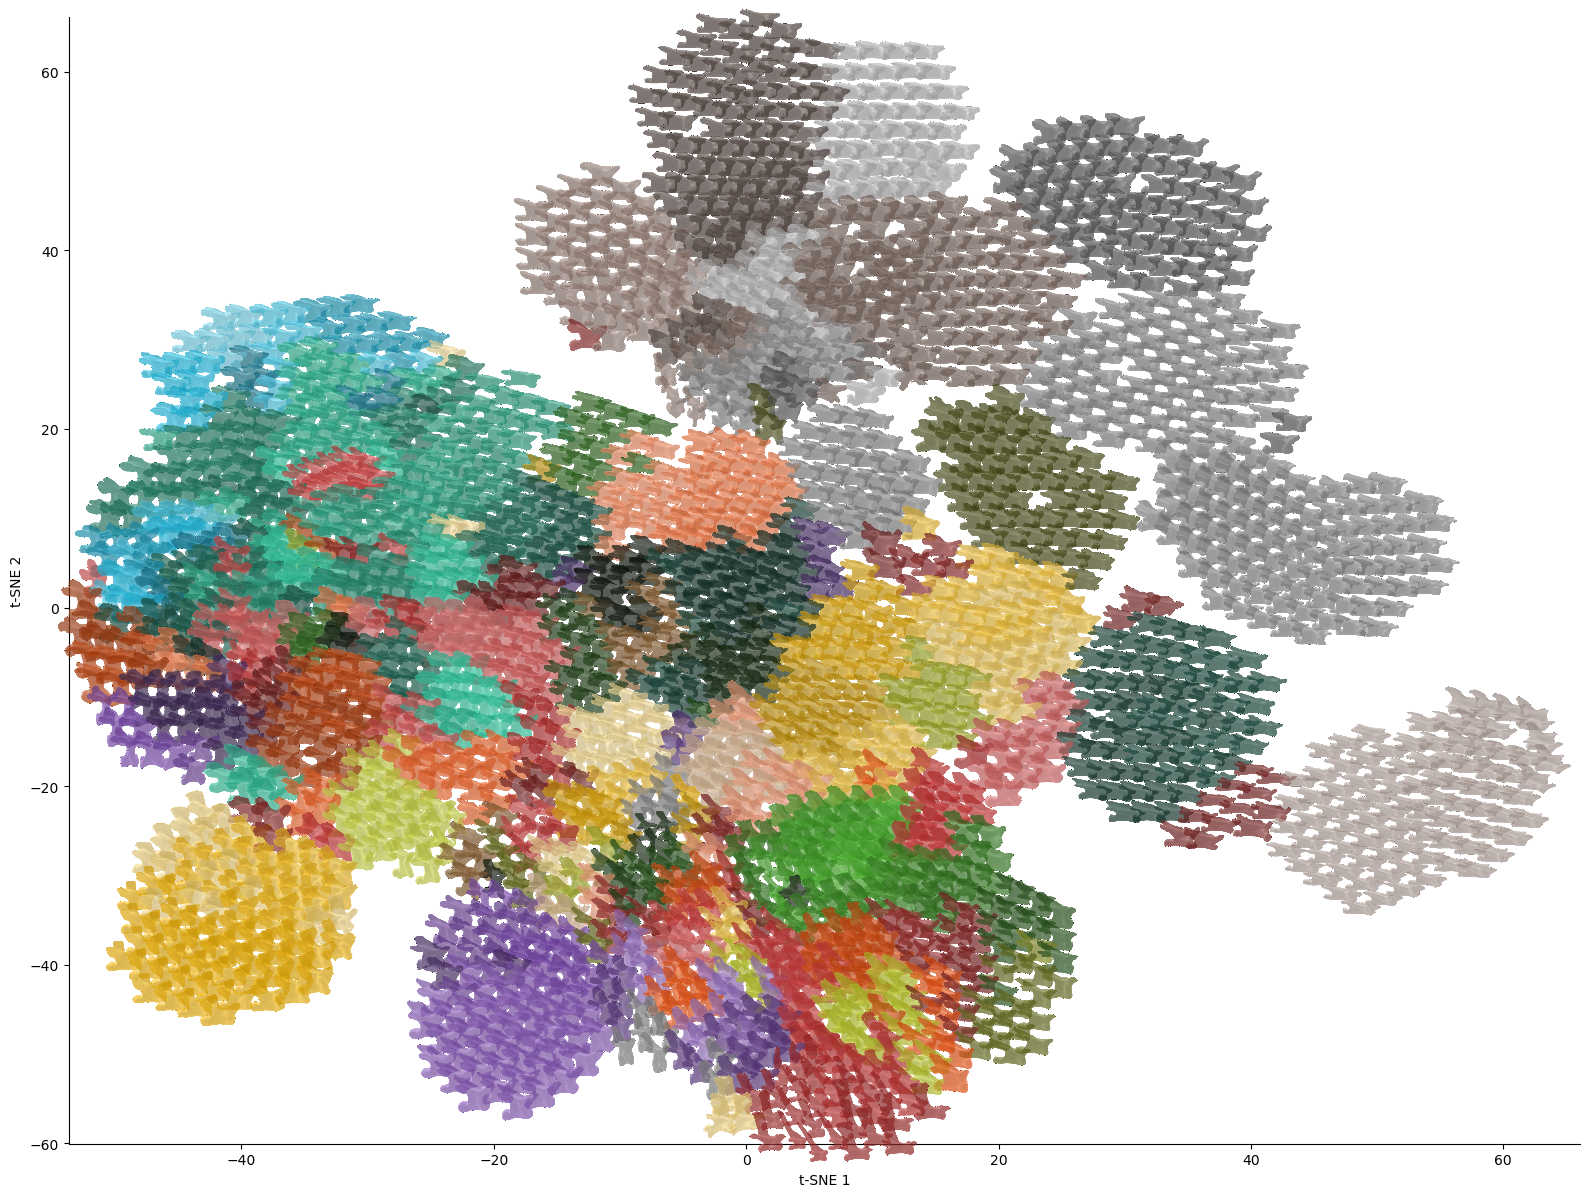

In [7]:
# t-SNE: every vertebra drawn as its rendering, optionally repelled so they overlap less

TSNE_KW = dict(n_components=2, perplexity=30, learning_rate=50, early_exaggeration=12,
               n_iter_without_progress=2000, metric="cosine", random_state=42)
THUMB_PT    = 30
VERT_ALPHA  = 0.7        # 1 = solid
SHOW_AXES   = True
SHOW_LEGEND = False
REPEL       = True
REPEL_KW    = dict(overlap=0.6,          # 1 = no overlap; lower lets dense clusters stay snug
                   spring=0.01,          # pull back toward the true position (higher = moves less)
                   iters=300,
                   step=0.25,            # damped push keeps crowded clusters stable
                   radius_scale=0.5)
LEADER_LINES = False                     # hairlines from true to repelled positions (busy with thousands)

tsne_coords = TSNE(**TSNE_KW).fit_transform(codes)

idx = np.array(sorted(coloured))
plot_thumbs(tsne_coords[idx], [coloured[i] for i in idx], f"{RUN}_tsne_vertebrae_{VIEW.lower()}",
            xlabel="t-SNE 1", ylabel="t-SNE 2", thumb_pt=THUMB_PT, vert_alpha=VERT_ALPHA,
            repel_kw=REPEL_KW if REPEL else None,
            leader_colors=[D.species_colors[D.labels[i][0]][:3] for i in idx] if LEADER_LINES else None,
            show_axes=SHOW_AXES, legend_colors=D.family_colors if SHOW_LEGEND else None, dpi=DPI_SAVE)

## Species means: one vertebra per species

No C5 for 30 species, using nearest vertebra instead: [('agamidae_uromastyx_sp_uf84845', 'c4'), ('amphisbaenidae_amphisbaena_bolivica', '005'), ('amphisbaenidae_bipes_sp', '005'), ('amphisbaenidae_blanus_cinereus', '005'), ('amphisbaenidae_cadea_blanoides', '005'), ('anguidae_celestus_hylaius_uf-75794', 'c4'), ('anguidae_pseudopus_apodus_ku87837', 'c3'), ('cordylidae_chamaesaura_aenea', 'c4')]
Saved -> run_v72_pca_1v2_species_means_c5_side.png / .pdf


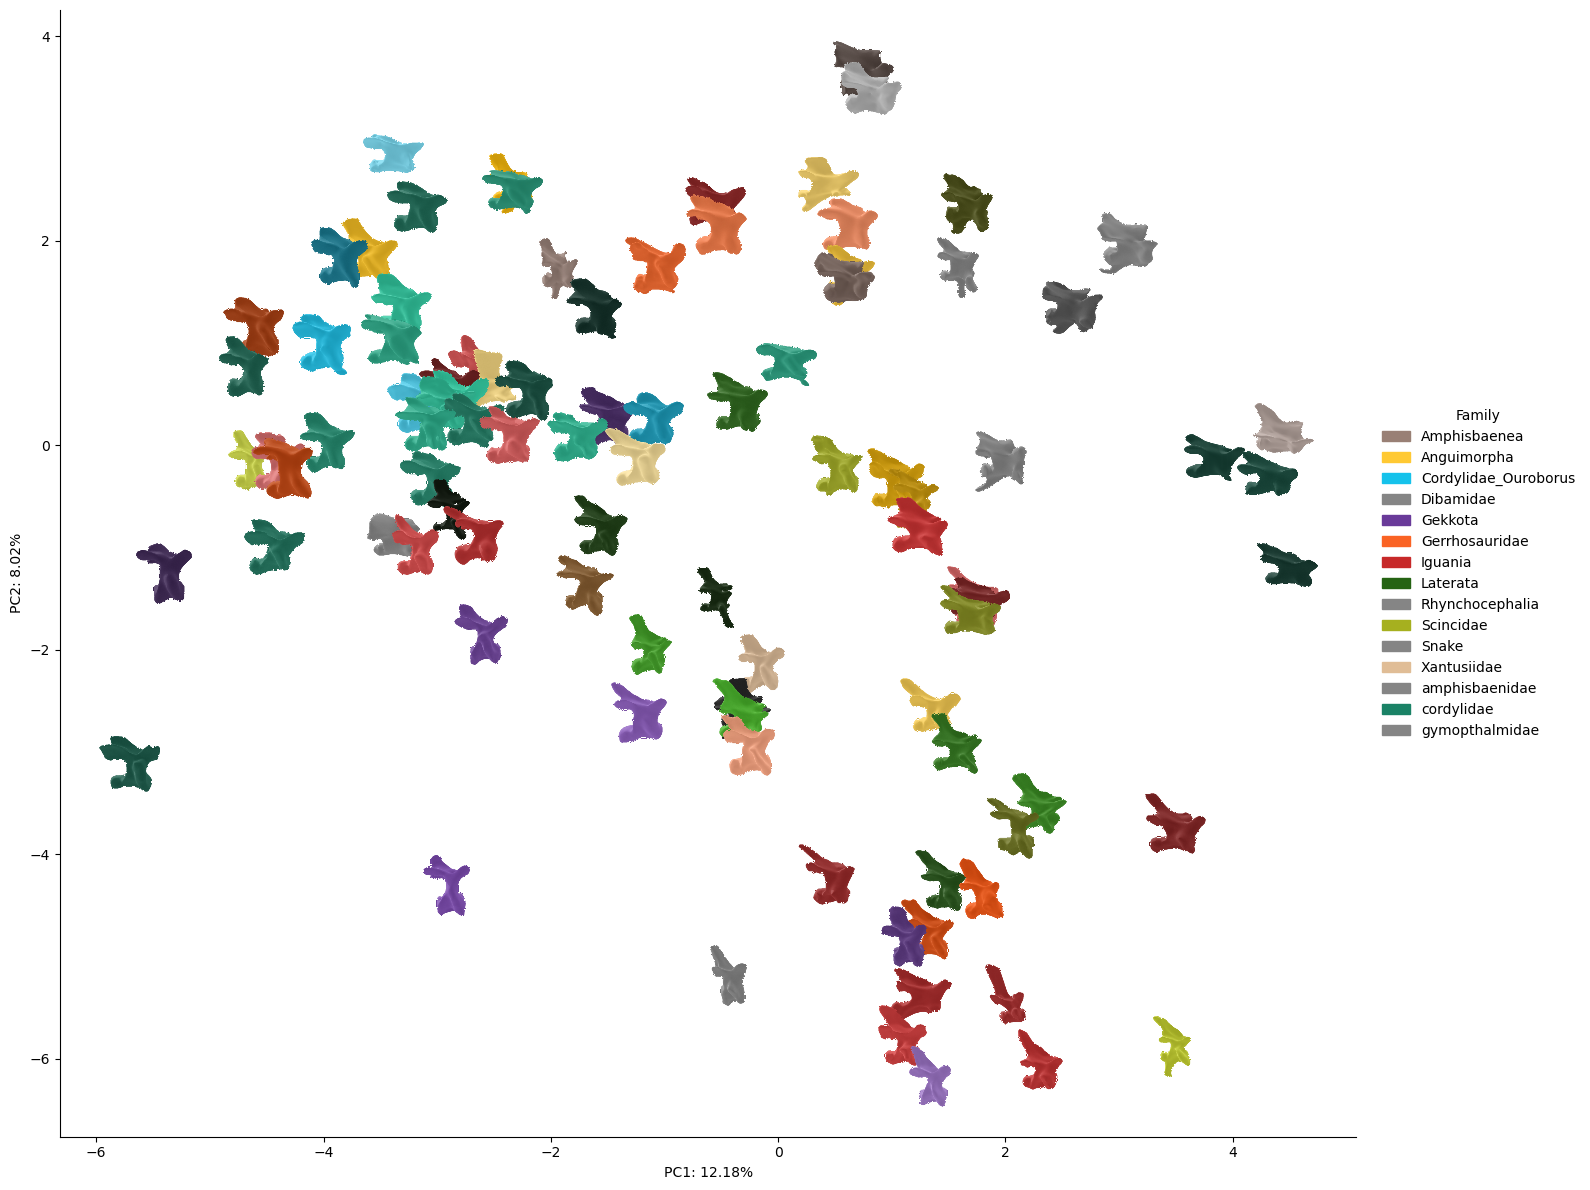

Saved -> run_v72_tsne_species_means_c5_side.png / .pdf


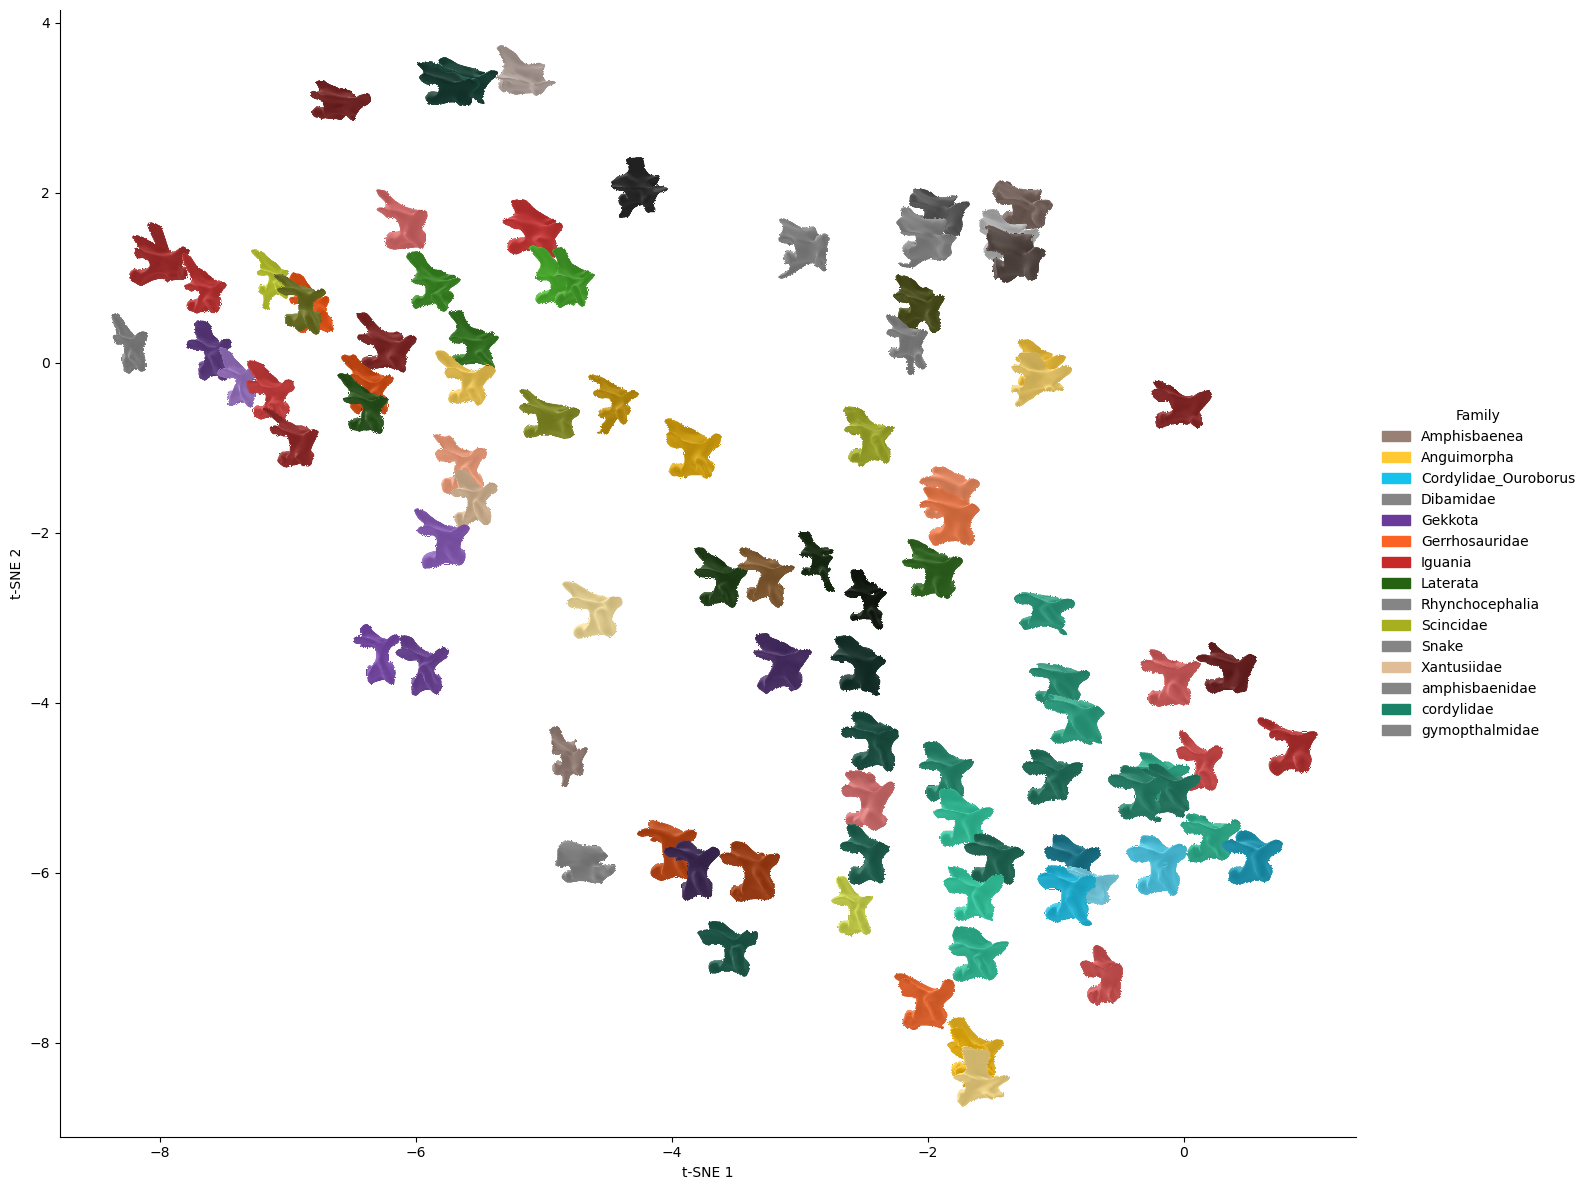

In [8]:
# Mean latent code per species, drawn as that species' C5 (or nearest available vertebra)

REP_VERT  = "C5"
THUMB_PT  = 45           # bigger now there are far fewer points
SHOW_AXES = True

rep_idx  = representative_vertebra(D, REP_VERT)
rep_imgs = [coloured[rep_idx[sp]] for sp in D.species_list]
subs = [(sp, D.labels[rep_idx[sp]][1]) for sp in D.species_list if D.labels[rep_idx[sp]][1].upper() != REP_VERT]
if subs:
    print(f"No {REP_VERT} for {len(subs)} species, using nearest vertebra instead: {subs[:8]}")

mean_codes = species_means(D, codes)

# PCA: same axes as the full plot
plot_thumbs(pca.transform(mean_codes)[:, :2], rep_imgs, f"{RUN}_pca_1v2_species_means_{REP_VERT.lower()}_{VIEW.lower()}",
            xlabel=f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%",
            ylabel=f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%",
            thumb_pt=THUMB_PT, show_axes=SHOW_AXES, legend_colors=D.family_colors, dpi=DPI_SAVE)

# t-SNE re-run on the species means (perplexity must be < number of species)
perp      = min(30, max(2, (len(D.species_list) - 1) // 3))
mean_tsne = TSNE(n_components=2, perplexity=perp, learning_rate=50, early_exaggeration=12,
                 metric="cosine", init="pca", random_state=42).fit_transform(mean_codes)
plot_thumbs(mean_tsne, rep_imgs, f"{RUN}_tsne_species_means_{REP_VERT.lower()}_{VIEW.lower()}",
            xlabel="t-SNE 1", ylabel="t-SNE 2",
            thumb_pt=THUMB_PT, show_axes=SHOW_AXES, legend_colors=D.family_colors, dpi=DPI_SAVE)

## Journal cover

Each species' vertebral column is a tapering curve through its vertebrae, neck to lower back, in the full
embedding. The species-mean C5 sits on top, repelled so thumbnails don't collide, with a hairline back to
its true position. Taxon names run along the bottom in a coloured-pencil hand.

Saved -> run_v72_tsne_cover_side.png / .pdf


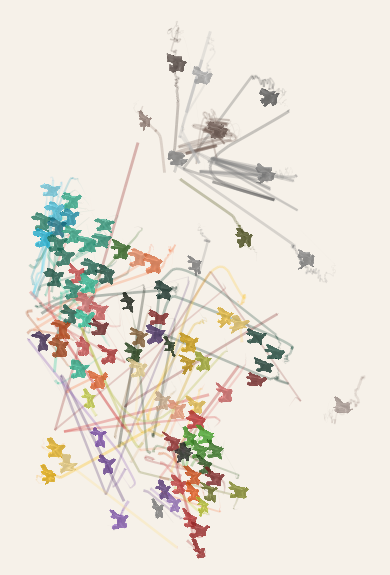

Saved -> run_v72_pca_cover_side.png / .pdf


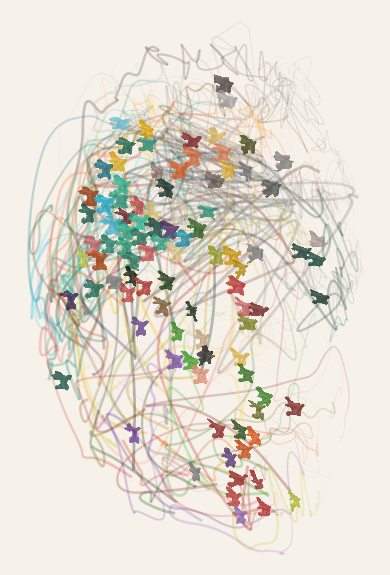

In [13]:
# Cover image

COVER = dict(size=(4.12, 6.1),
             bg="#f6f1e9",             # warm paper; try "#0f1b2d" for a deep-navy night version
             ink="#3b3a36",            # leader lines (use "#e9e4da" on a dark background)
             plot_top=0.97,            # top edge of the plot area (figure fraction)
             spine_w=(2.1, 0.2),       # column line width at the first and last vertebra
             spine_alpha=(0.3, 0.02),  # column opacity at the first and last vertebra
             thumb_pt=15,              # longest side of each thumbnail, in points
             vert_alpha=0.8,           # 1 = solid
             key_gap=0.005)            # gap between key and plot (figure fraction; negative overlaps)
REPEL_KW = dict(overlap=0.6,           # higher pushes thumbnails further apart (1.0 = edges just touch)
                spring=0.02,           # pull back toward the true position (lower = moves further)
                iters=400,
                step=0.5,
                radius_scale=0.65)
SHOW_KEY  = False
HAND_FONT = "homemade_apple"           # see HAND_FONTS in the functions cell
KEY = dict(left=0.06, right=0.94,      # key spans this width of the page (figure fractions)
           bottom=0.025,               # bottom edge of the key
           cols=3,
           size=13,                    # letter height in points
           leading=1.15,               # line spacing, in multiples of size
           case="regular",             # "regular", "title" or "upper"
           passes=3,                   # layered fills; more = denser, waxier colour
           fill_alpha=0.5,             # opacity per layer
           jitter=0.2,                 # offset between layers, in points
           fade=(1.0, 0.2),            # opacity at the start and end of each name
           exclude={"Snake", "Cordylidae_Ouroborus", "amphisbaenidae"},
           rename={"Amphisbaenea": "Amphisbaenia"})

font = load_hand_font(HAND_FONT) if SHOW_KEY else None
for name, coords in [("tsne", tsne_coords), ("pca", pca_coords[:, :2])]:
    plot_cover(D, coords, rep_imgs, f"{RUN}_{name}_cover_{VIEW.lower()}", **COVER,
               repel_kw=REPEL_KW, key=KEY if SHOW_KEY else None, font=font, dpi=DPI_SAVE)